# Section 4.3 — Joint-Distribution Fidelity and Empirical Support

This notebook consumes completed analysis artifacts only. It does **not** rerun synthesis or modify source data. The weighted VISTA seed is the primary joint-distribution reference; the fixed BN pool is a secondary generated-support reference.

**Repeat convention:** IPF, BN, and WGAN use ten observed repetitions. Each SAA variant has one observed result; at the author's direction, it is represented as ten identical analytical repetitions (SD = 0). These copies are explicitly labelled and must not be described as ten independent reruns.

## 1. Setup and paths

In [1]:
from IPython.display import display, Markdown, Image
from PopSynthesis.analyse.paper_section_4_3 import (
    paths, load_inputs, validate_inputs, joint_order_summary, figure_joint_order,
    tradeoff_summary, figure_tradeoff, support_summary, conditional_diagnostics,
    diversity_summary, cross_checks, write_findings, configure_style,
)

configure_style()
P = paths()
P

{'root': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash'),
 'analysis': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis'),
 'output': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_3'),
 'figures': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_3/figures'),
 'tables': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_3/tables'),
 'supplementary': PosixPath('/Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_3/supplementary')}

## 2. Load and validate existing results

In [2]:
data = load_inputs(P)
validation = validate_inputs(data, P)
display(validation)
display(data['catalog'].groupby('run_id')['repeat'].nunique().rename('observed_repeats').to_frame())

,check,passed,detail
0,all_nine_methods,True,Found 9 methods
1,weighted_VISTA_reference,True,joint reference identifier is weighted_seed; m...
2,JS_distance_bounds,True,"range [0.005725, 0.661720]"
3,JS_distance_definition,True,metrics.py calls scipy.spatial.distance.jensen...
4,expected_joint_subsets,True,"expected={2: 10, 3: 10, 4: 5, 5: 1}; observed=..."
5,observed_repeat_catalog,True,Observed SAA repeats=1 each; IPF/BN/WGAN repea...
6,paper_repeat_assumption,True,SAA repeat 1 is copied analytically to repeats...


,observed_repeats
run_id,
bn_exact_hhsize,10
ipf_bn_pool,10
ipf_original_weighted_seed,10
saa_bn_pool_seed_only,1
saa_original_relax_empty_rows_columns,1
saa_original_seed_only,1
saa_original_unrestricted,1
saa_seed_free_all_zero,1
wgan_exact_hhsize,10


JS distance was calculated by the analysis pipeline using `scipy.spatial.distance.jensenshannon(..., base=2)`. It is the square root of JS divergence and therefore lies in [0, 1]. The interaction-order analysis averages already-calculated subset distances, never probability distributions.

## 3. Joint JS analysis by interaction order

In [3]:
joint_per_repeat, joint_summary = joint_order_summary(data, P)
display(joint_summary)

,run_id,method,interaction_order,mean_js_distance,sd_across_runs,min_js_distance,max_js_distance,number_of_subsets,repeats_reported,repeat_basis
0,bn_exact_hhsize,BN,2,0.071810,0.000048,0.071752,0.071895,10,10,10 observed repeats
1,bn_exact_hhsize,BN,3,0.130824,0.000069,0.130671,0.130908,10,10,10 observed repeats
2,bn_exact_hhsize,BN,4,0.206894,0.000124,0.206669,0.207031,5,10,10 observed repeats
3,bn_exact_hhsize,BN,5,0.310042,0.000239,0.309714,0.310486,1,10,10 observed repeats
4,ipf_bn_pool,IPF BN-pool,2,0.188402,0.000123,0.188268,0.188713,10,10,10 observed repeats
5,ipf_bn_pool,IPF BN-pool,3,0.251004,0.000136,0.250857,0.251344,10,10,10 observed repeats
6,ipf_bn_pool,IPF BN-pool,4,0.322768,0.000132,0.322615,0.323070,5,10,10 observed repeats
7,ipf_bn_pool,IPF BN-pool,5,0.412482,0.000149,0.412235,0.412674,1,10,10 observed repeats
8,ipf_original_weighted_seed,IPF Original,2,0.177713,0.000075,0.177616,0.177870,10,10,10 observed repeats
9,ipf_original_weighted_seed,IPF Original,3,0.224677,0.000096,0.224524,0.224868,10,10,10 observed repeats


## 4. Figure A — Joint-distribution fidelity by interaction order

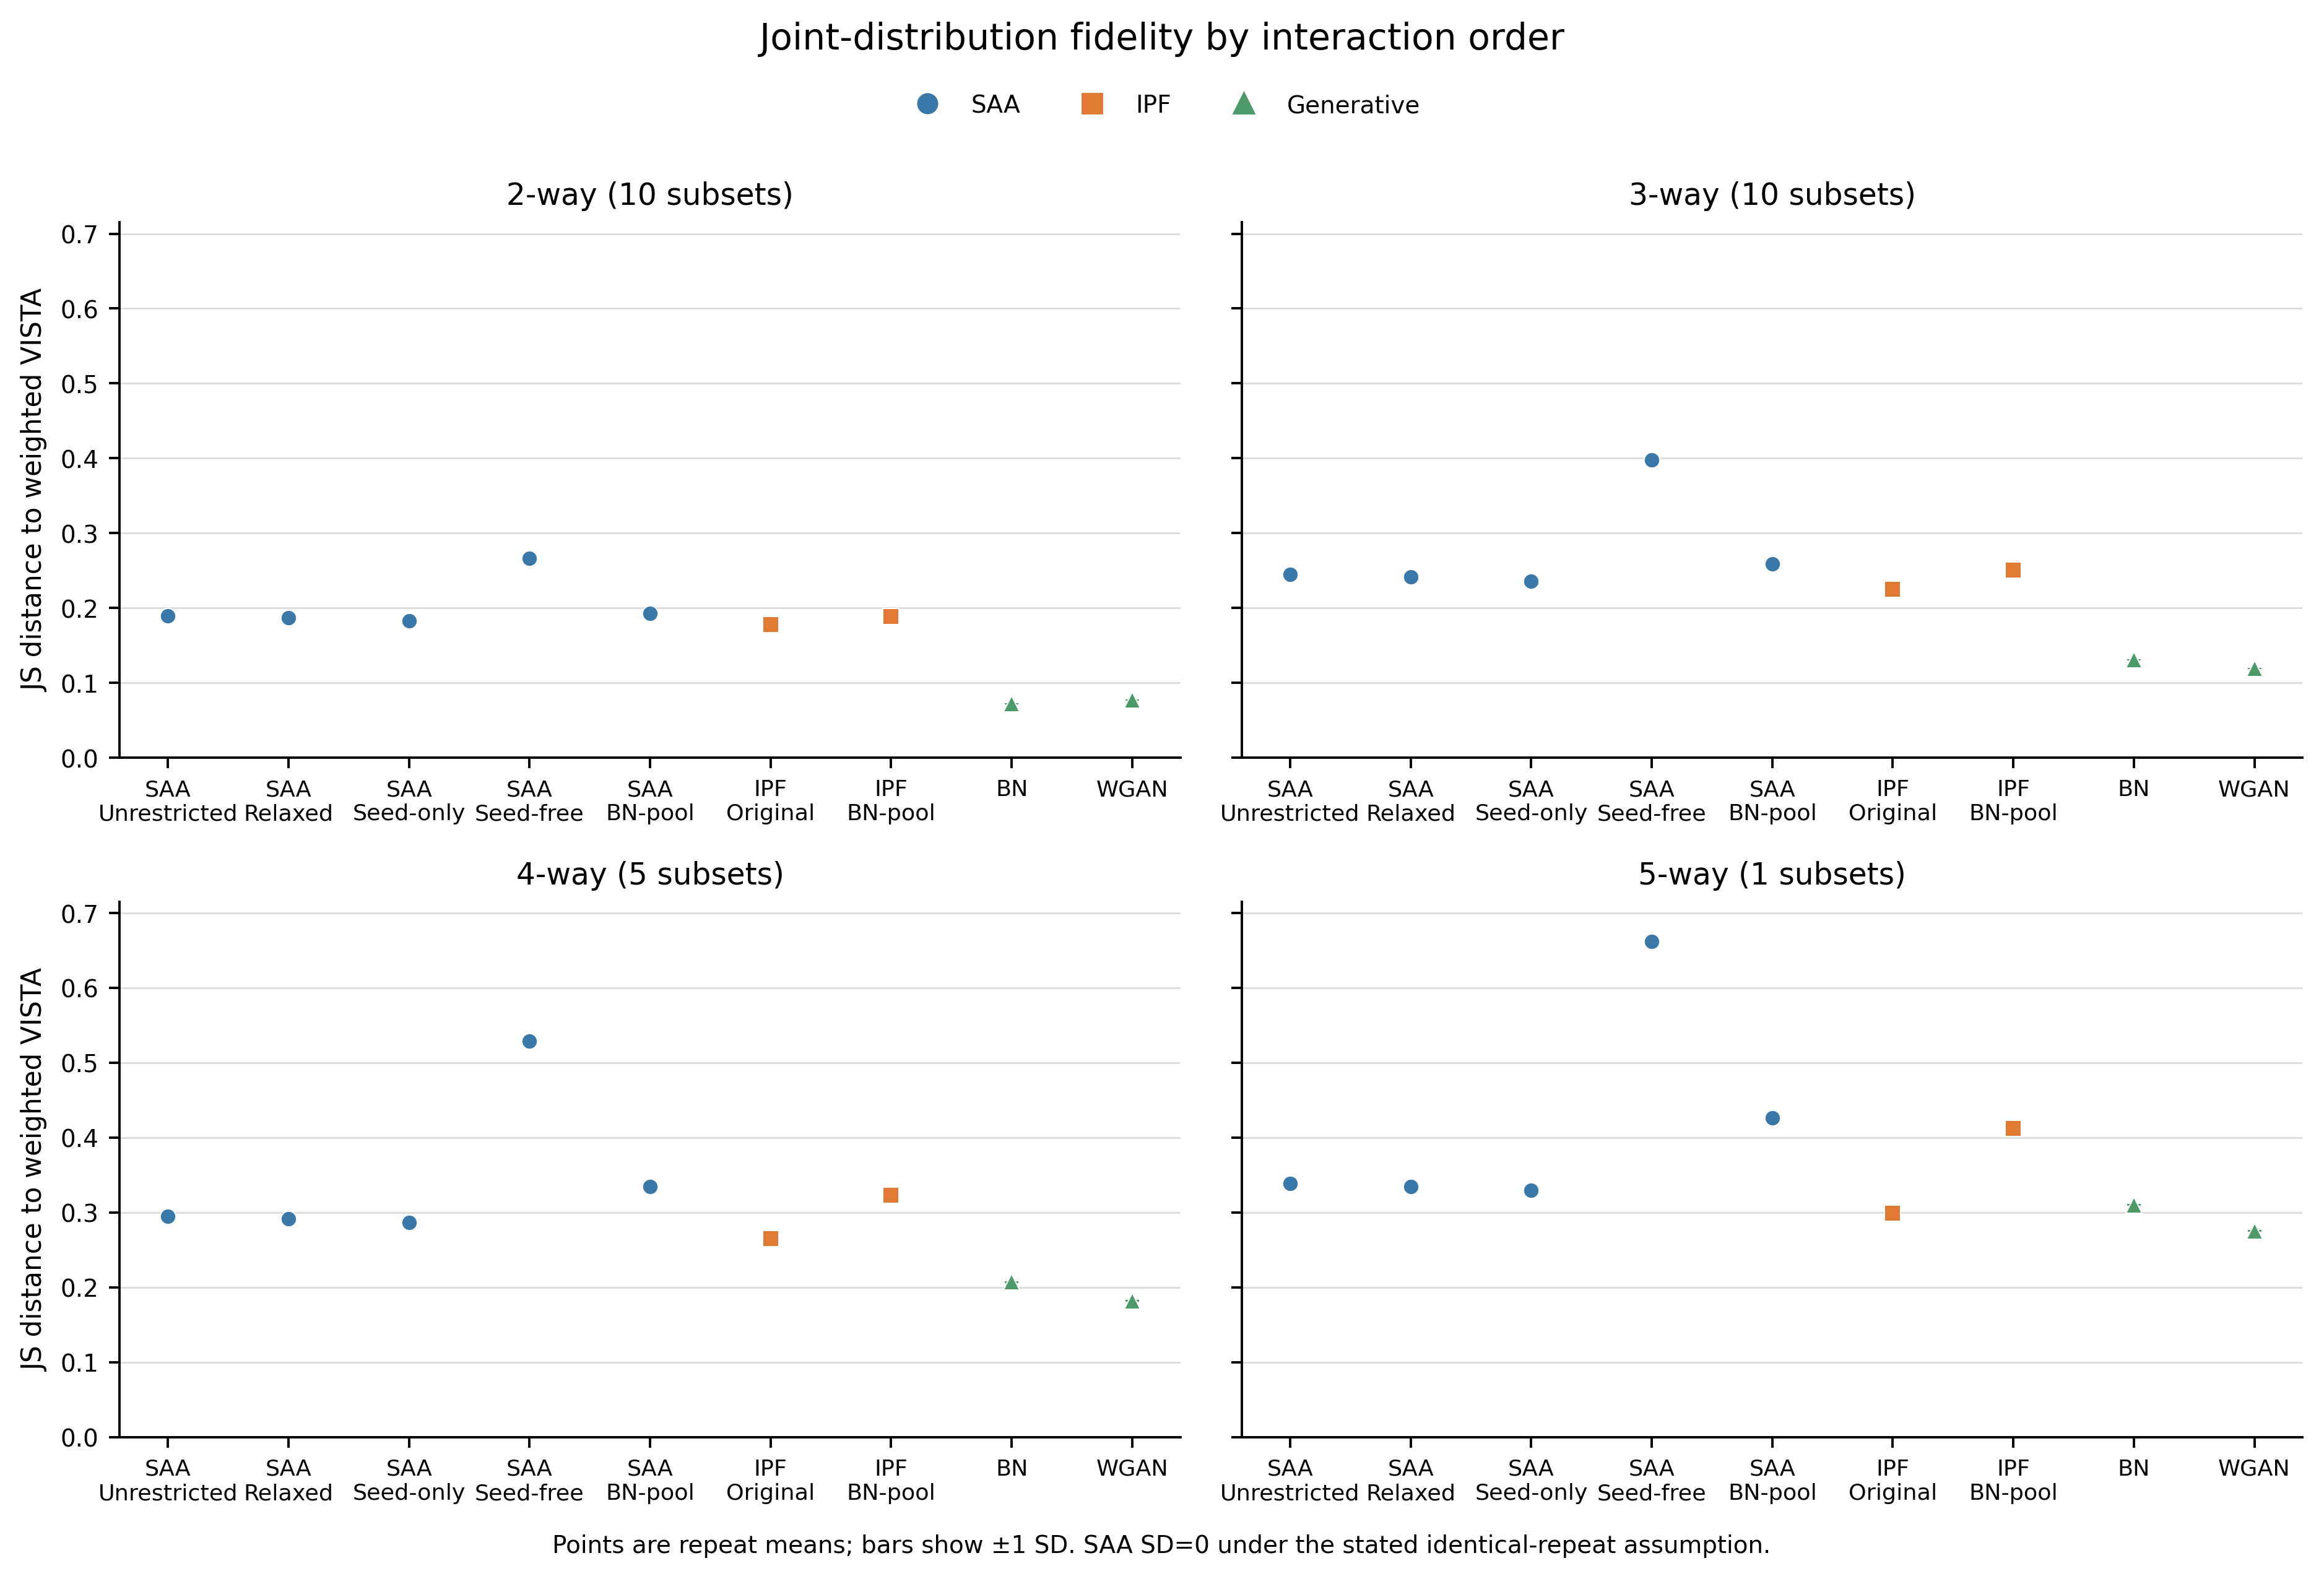

In [4]:
figure_joint_order(joint_summary, P)
display(Image(filename=P['figures'] / 'figure_A_joint_fidelity_by_order.png'))

## 5. Census–joint fidelity comparison

In [5]:
tradeoff = tradeoff_summary(data, joint_per_repeat, P)
display(tradeoff)

,run_id,macro_census_tvd_mean,macro_census_tvd_sd,five_way_js_mean,five_way_js_sd,repeats_reported,method,non_dominated_on_these_two_metrics,repeat_basis
0,saa_original_unrestricted,0.000000,0.000000,0.338496,0.000000,10,SAA Unrestricted,True,1 observed result represented as 10 identical ...
1,saa_original_relax_empty_rows_columns,0.014322,0.000000,0.334689,0.000000,10,SAA Relaxed,True,1 observed result represented as 10 identical ...
2,saa_original_seed_only,0.017678,0.000000,0.329800,0.000000,10,SAA Seed-only,True,1 observed result represented as 10 identical ...
3,saa_seed_free_all_zero,0.000000,0.000000,0.661720,0.000000,10,SAA Seed-free,False,1 observed result represented as 10 identical ...
4,saa_bn_pool_seed_only,0.003511,0.000000,0.426269,0.000000,10,SAA BN-pool,False,1 observed result represented as 10 identical ...
5,ipf_original_weighted_seed,0.029920,0.000213,0.298949,0.000135,10,IPF Original,True,10 observed repeats
6,ipf_bn_pool,0.028874,0.000291,0.412482,0.000149,10,IPF BN-pool,False,10 observed repeats
7,bn_exact_hhsize,0.173616,0.000285,0.310042,0.000239,10,BN,False,10 observed repeats
8,wgan_exact_hhsize,0.171533,0.000365,0.275417,0.000234,10,WGAN,True,10 observed repeats


## 6. Figure B — Census alignment versus five-way joint fidelity

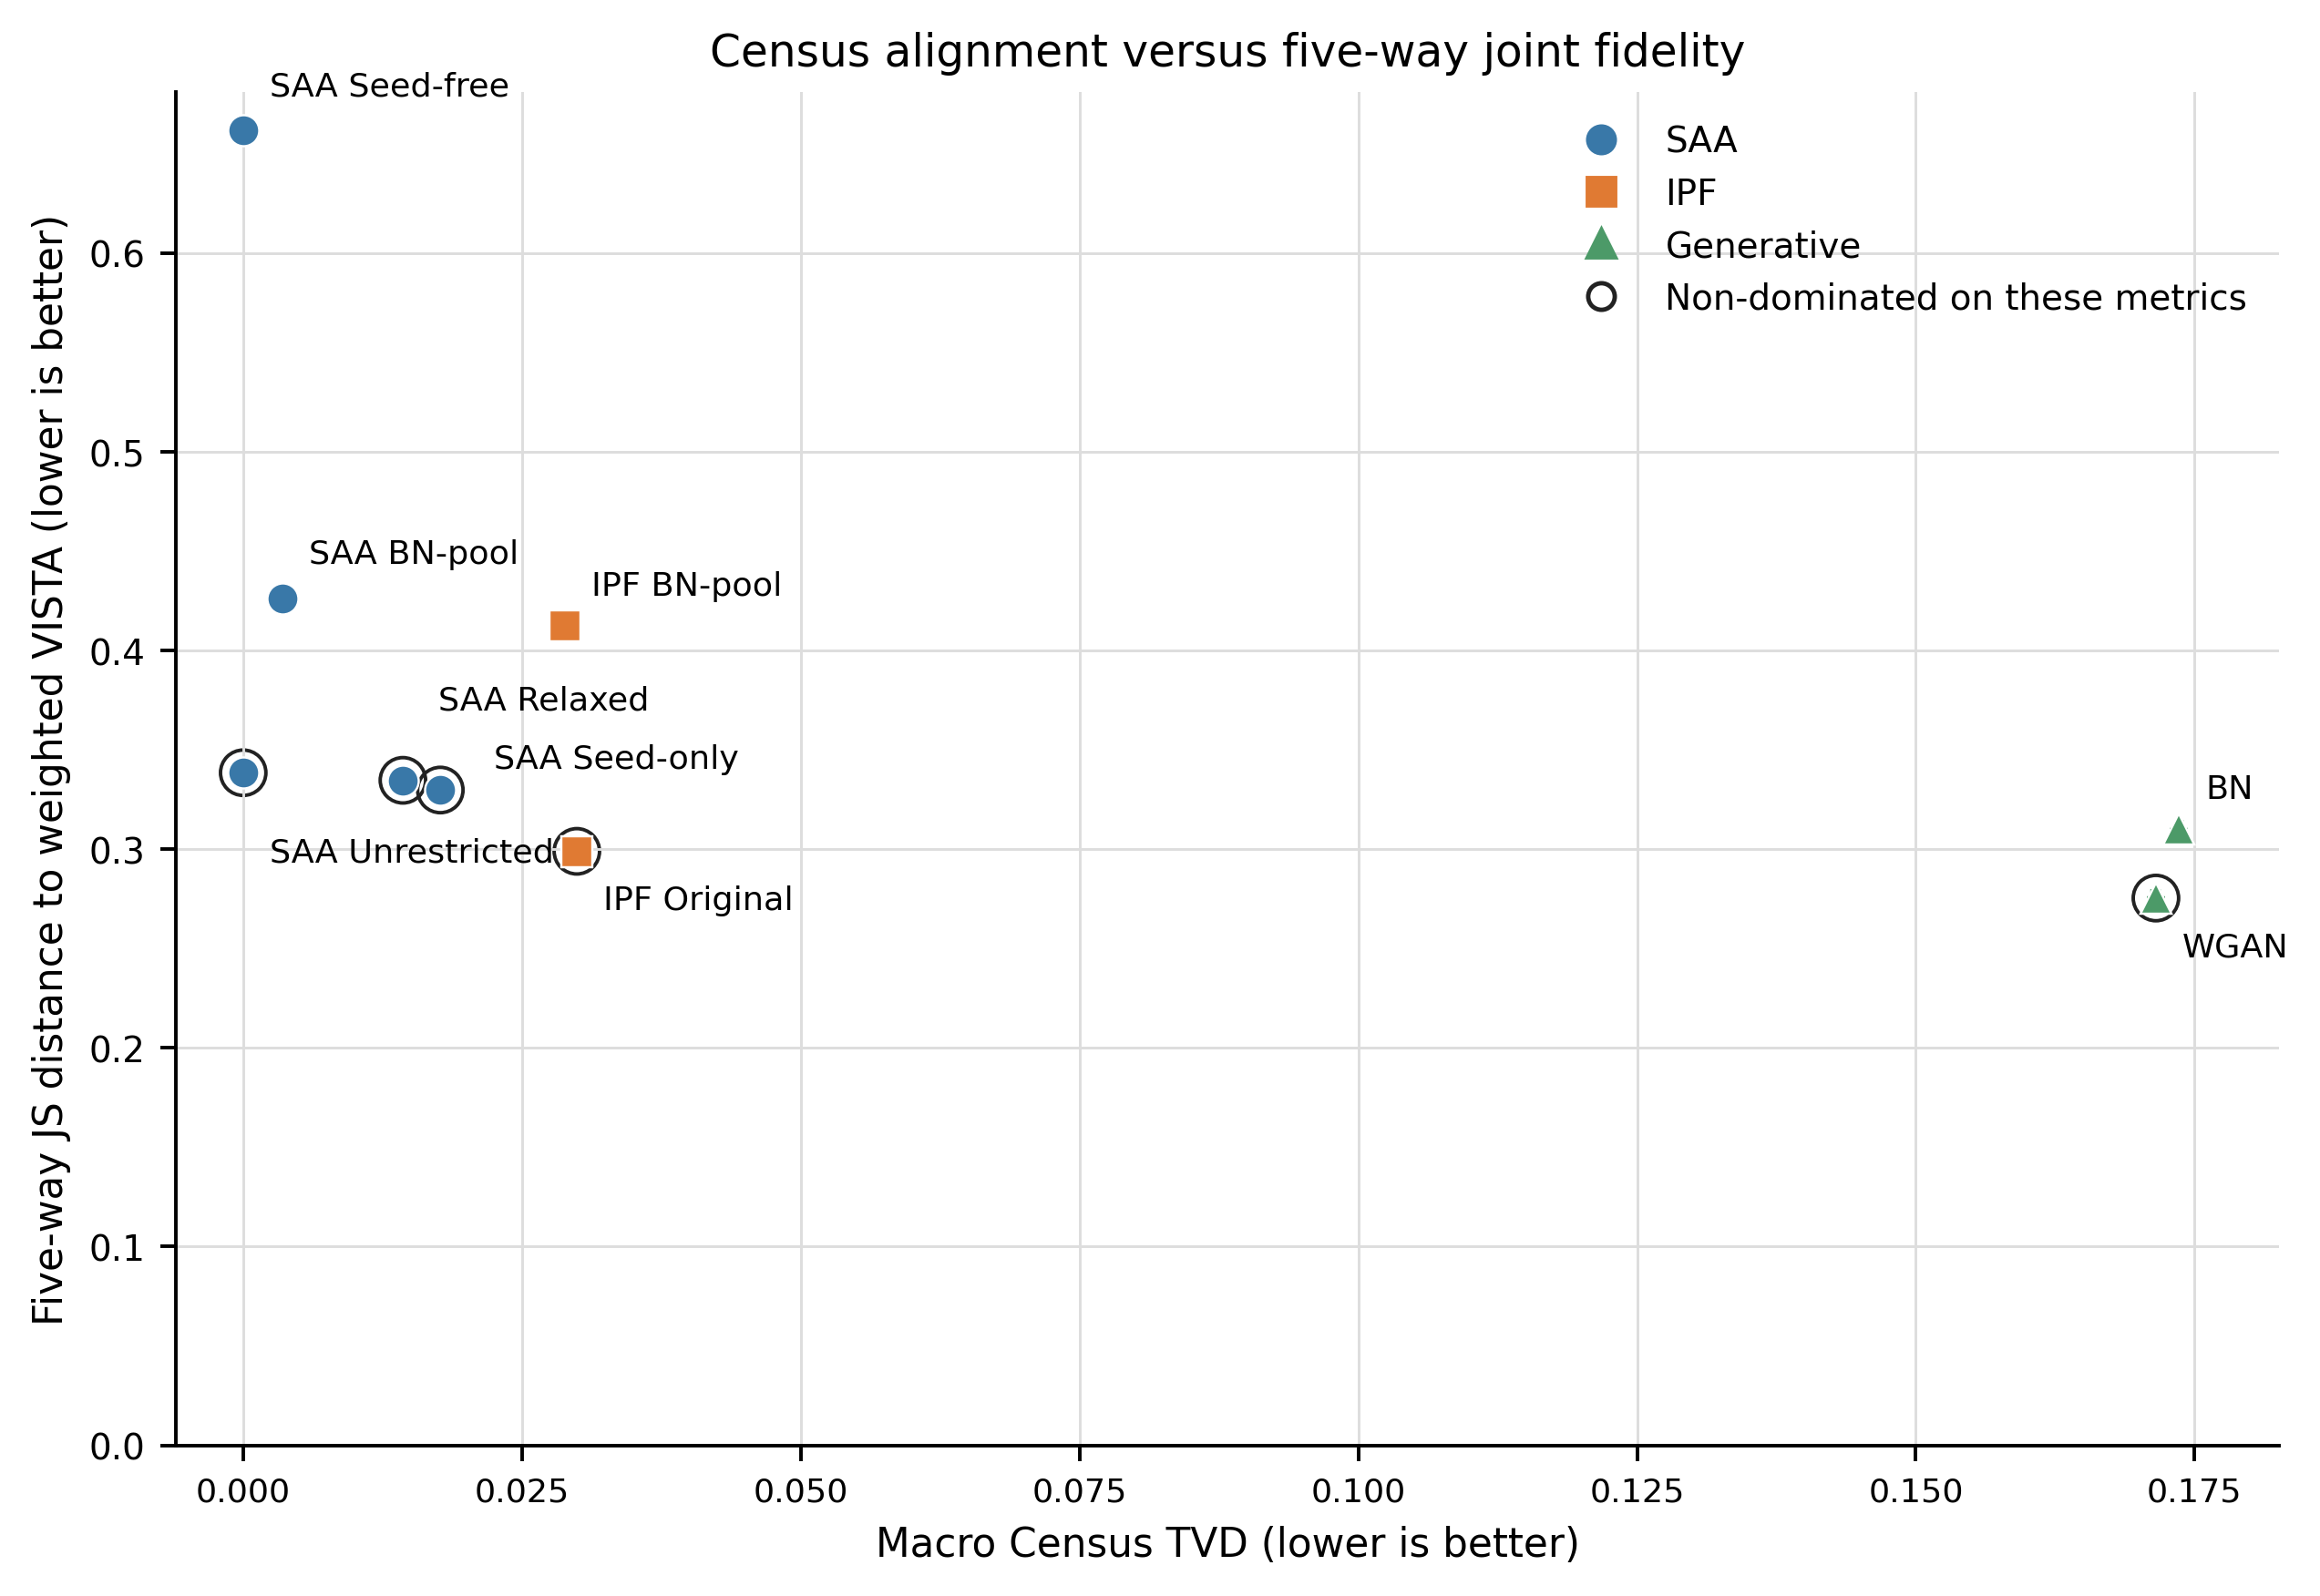

In [6]:
figure_tradeoff(tradeoff, P)
display(Image(filename=P['figures'] / 'figure_B_census_vs_five_way_joint.png'))

## 7. Empirical-support provenance

In [7]:
support = support_summary(data, P)
display(support)
print((P['tables'] / 'support_provenance_table.tex').read_text())

,run_id,method,repeats_reported,VISTA-supported_mean_percent,VISTA-supported_sd_percent,BN-only_mean_percent,BN-only_sd_percent,Unconfirmed_mean_percent,Unconfirmed_sd_percent,repeat_basis
0,saa_original_unrestricted,SAA Unrestricted,10,93.478984,0.000000,1.600680,0.000000,4.920336,0.000000,1 observed result represented as 10 identical ...
1,saa_original_relax_empty_rows_columns,SAA Relaxed,10,99.273992,0.000000,0.018098,0.000000,0.707911,0.000000,1 observed result represented as 10 identical ...
2,saa_original_seed_only,SAA Seed-only,10,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1 observed result represented as 10 identical ...
3,saa_seed_free_all_zero,SAA Seed-free,10,78.939775,0.000000,12.961998,0.000000,8.098227,0.000000,1 observed result represented as 10 identical ...
4,saa_bn_pool_seed_only,SAA BN-pool,10,88.527081,0.000000,11.472919,0.000000,0.000000,0.000000,1 observed result represented as 10 identical ...
5,ipf_original_weighted_seed,IPF Original,10,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10 observed repeats
6,ipf_bn_pool,IPF BN-pool,10,90.382378,0.013378,9.617622,0.013378,0.000000,0.000000,10 observed repeats
7,bn_exact_hhsize,BN,10,92.812561,0.014930,7.019024,0.015023,0.168414,0.002949,10 observed repeats
8,wgan_exact_hhsize,WGAN,10,94.311714,0.016857,5.051274,0.016049,0.637012,0.004349,10 observed repeats


\begin{tabular}{lrrrrrr}
\toprule
Method & \multicolumn{2}{c}{VISTA-supported (\%)} & \multicolumn{2}{c}{BN-only (\%)} & \multicolumn{2}{c}{Unconfirmed (\%)} \\
 & Mean & SD & Mean & SD & Mean & SD \\
\midrule
SAA Unrestricted & 93.479 & 0.000 & 1.601 & 0.000 & 4.920 & 0.000 \\
SAA Relaxed & 99.274 & 0.000 & 0.018 & 0.000 & 0.708 & 0.000 \\
SAA Seed-only & 100.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.000 \\
SAA Seed-free & 78.940 & 0.000 & 12.962 & 0.000 & 8.098 & 0.000 \\
SAA BN-pool & 88.527 & 0.000 & 11.473 & 0.000 & 0.000 & 0.000 \\
IPF Original & 100.000 & 0.000 & 0.000 & 0.000 & 0.000 & 0.000 \\
IPF BN-pool & 90.382 & 0.013 & 9.618 & 0.013 & 0.000 & 0.000 \\
BN & 92.813 & 0.015 & 7.019 & 0.015 & 0.168 & 0.003 \\
WGAN & 94.312 & 0.017 & 5.051 & 0.016 & 0.637 & 0.004 \\
\bottomrule
\end{tabular}
% SAA standard deviations are zero under the identical-repeat assumption.



The three categories are mutually exclusive. “Unconfirmed” means absent from both empirical support pools; it does not mean structurally infeasible.

## 8. Conditional relationship diagnostics and supplementary figure

,rank,conditioning_attribute,outcome_attribute,relationship,methods_with_conditional_js,methods_with_conditional_tv,mean_method_conditional_js,max_method_conditional_js,method_spread_conditional_js,mean_method_conditional_tv,max_method_conditional_tv,method_spread_conditional_tv,SAA_policy_spread_conditional_tv,scaled_method_spread_conditional_tv,scaled_SAA_policy_spread_conditional_tv,scaled_mean_method_conditional_tv,diagnostic_score,priority_reason
0,1,hhsize,hhinc,hhinc | hhsize,9,9,0.205760,0.375742,0.372183,0.165282,0.324239,0.321958,0.136953,1.000000,0.665119,0.991031,0.880998,"Ranks method separation (45%), SAA-policy sepa..."
1,2,hhinc,hhsize,hhsize | hhinc,0,9,NaN,NaN,NaN,0.101232,0.280707,0.235645,0.205908,0.731910,1.000000,0.606987,0.800757,"Ranks method separation (45%), SAA-policy sepa..."
2,3,hhsize,totalvehs,totalvehs | hhsize,9,9,0.077210,0.251035,0.249830,0.061227,0.238676,0.237766,0.197779,0.738499,0.960525,0.367120,0.741932,"Ranks method separation (45%), SAA-policy sepa..."
3,4,owndwell,hhsize,hhsize | owndwell,9,9,0.108040,0.254955,0.171145,0.073741,0.254077,0.208556,0.201059,0.647772,0.976452,0.442151,0.721686,"Ranks method separation (45%), SAA-policy sepa..."
4,5,totalvehs,hhsize,hhsize | totalvehs,9,9,0.106028,0.278959,0.204224,0.074006,0.243106,0.198500,0.190672,0.616540,0.926009,0.443738,0.690294,"Ranks method separation (45%), SAA-policy sepa..."
5,6,totalvehs,hhinc,hhinc | totalvehs,9,9,0.198192,0.291004,0.216353,0.166778,0.269981,0.231462,0.092075,0.718920,0.447169,1.000000,0.680023,"Ranks method separation (45%), SAA-policy sepa..."
6,7,hhsize,owndwell,owndwell | hhsize,9,9,0.099745,0.242618,0.224169,0.092816,0.236816,0.218357,0.144498,0.678216,0.701761,0.556524,0.662118,"Ranks method separation (45%), SAA-policy sepa..."
7,8,owndwell,hhinc,hhinc | owndwell,9,9,0.197047,0.264494,0.189678,0.165315,0.232063,0.186515,0.053989,0.579315,0.262200,0.991226,0.550707,"Ranks method separation (45%), SAA-policy sepa..."
8,9,dwelltype,hhinc,hhinc | dwelltype,9,9,0.190836,0.263863,0.224732,0.159489,0.229589,0.191752,0.046724,0.595579,0.226917,0.956298,0.538691,"Ranks method separation (45%), SAA-policy sepa..."
9,10,hhinc,totalvehs,totalvehs | hhinc,0,9,NaN,NaN,NaN,0.073949,0.186974,0.146420,0.143935,0.454779,0.699028,0.443396,0.537989,"Ranks method separation (45%), SAA-policy sepa..."


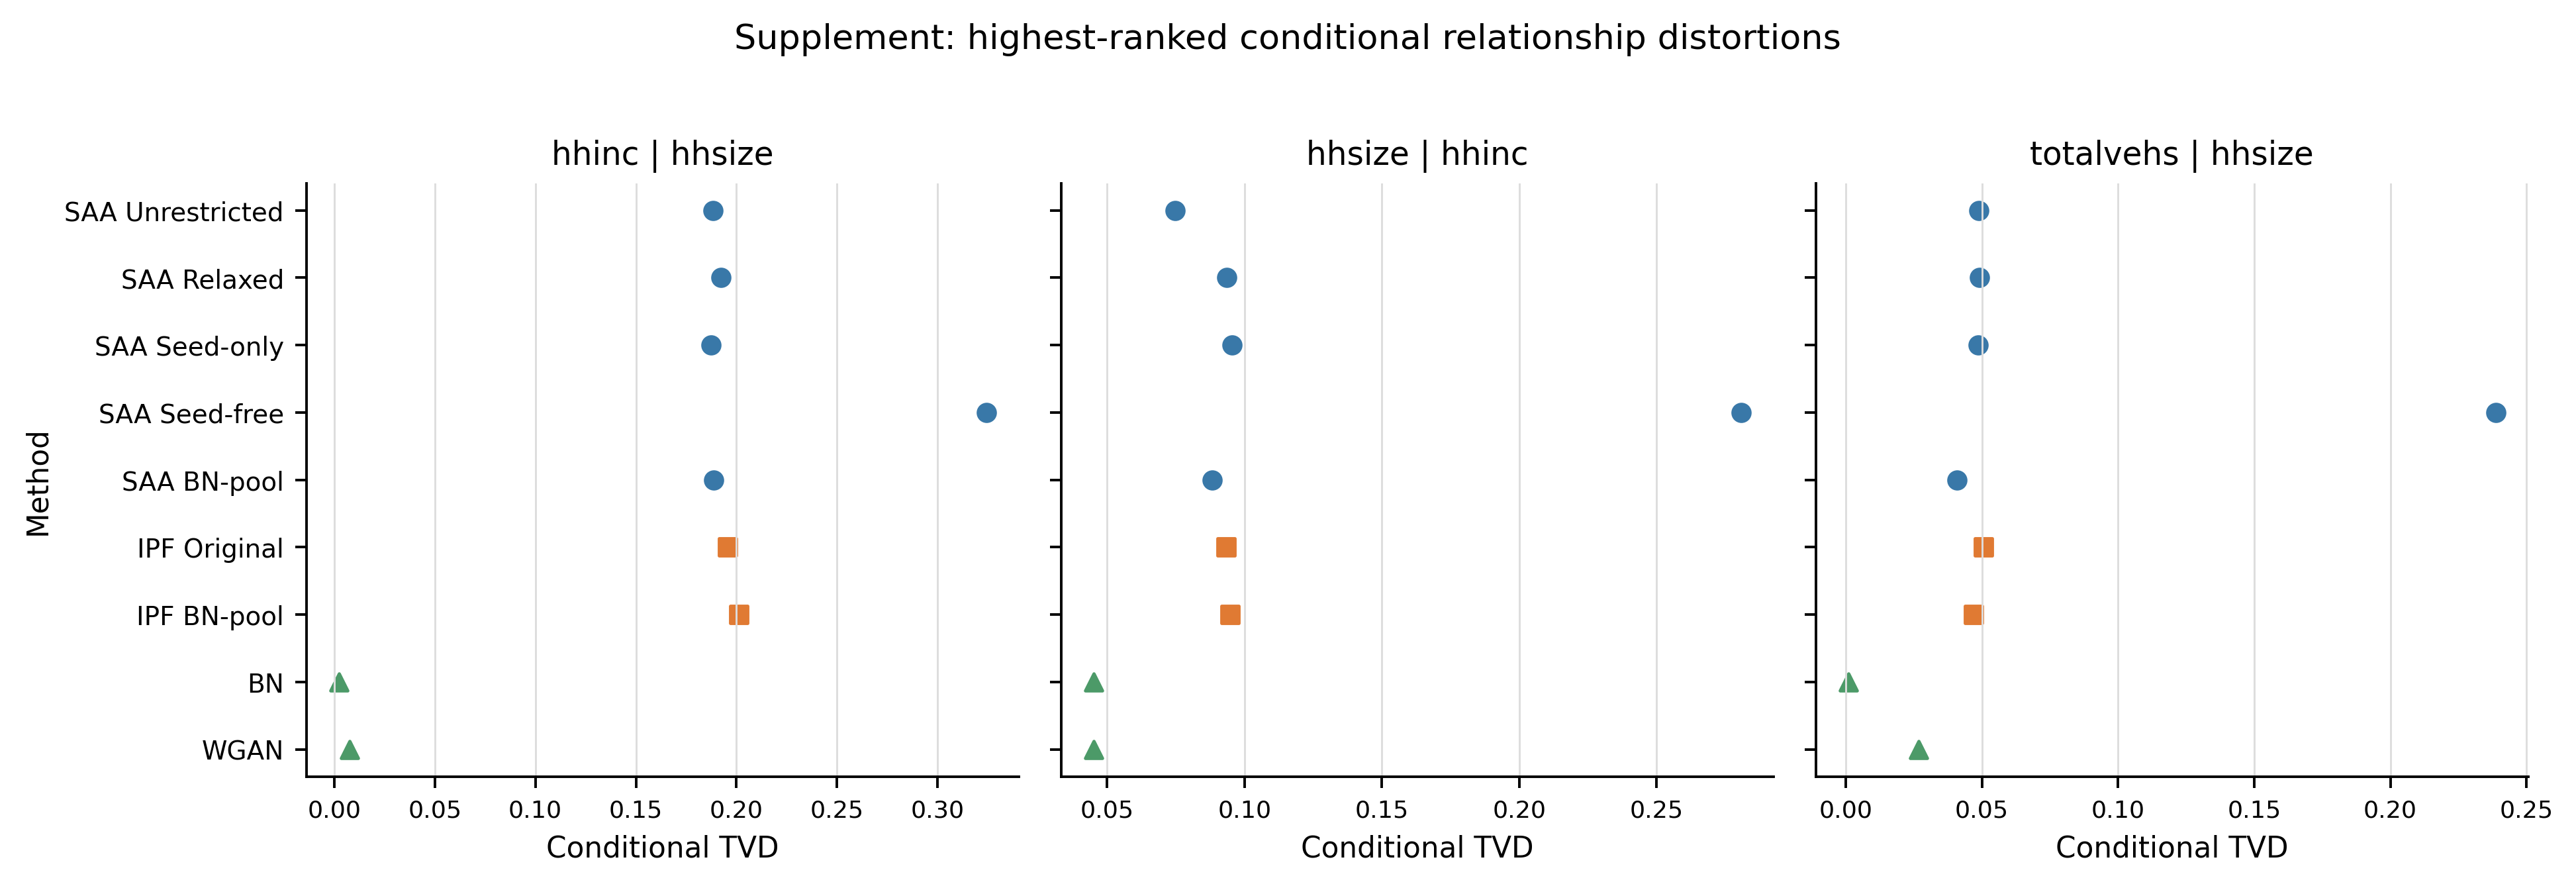

In [8]:
conditional = conditional_diagnostics(data, P)
display(conditional.head(10))
display(Image(filename=P['supplementary'] / 'conditional_relationship_diagnostics.png'))

The ranking is diagnostic rather than inferential. It weights between-method separation (45%), variation among SAA support policies (35%), and average distortion (20%). The supplementary plot reports conditional TVD from the existing detailed analysis.

## 9. Diversity analysis

In [9]:
diversity = diversity_summary(data, P)
display(diversity)

,run_id,occupied_five_way_mean,occupied_five_way_sd,effective_diversity_mean,effective_diversity_sd,unconfirmed_mass_mean_percent,unconfirmed_mass_sd_percent,distinct_unconfirmed_mean,distinct_unconfirmed_sd,mean_nearest_VISTA_hamming_mass_weighted,mean_nearest_BN_pool_hamming_mass_weighted,method,effective_diversity_definition,interpretation_note
0,saa_original_unrestricted,7230.0,0.000000,1350.958590,0.000000,4.920336,0.000000,1811.0,0.000000,1.069599,1.004400,SAA Unrestricted,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
1,saa_original_relax_empty_rows_columns,3633.0,0.000000,1182.679166,0.000000,0.707911,0.000000,354.0,0.000000,1.275900,1.049787,SAA Relaxed,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
2,saa_original_seed_only,3271.0,0.000000,1169.421135,0.000000,0.000000,0.000000,0.0,0.000000,NaN,NaN,SAA Seed-only,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
3,saa_seed_free_all_zero,5220.0,0.000000,1140.330988,0.000000,8.098227,0.000000,1128.0,0.000000,1.022388,1.001107,SAA Seed-free,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
4,saa_bn_pool_seed_only,8188.0,0.000000,1555.685744,0.000000,0.000000,0.000000,0.0,0.000000,NaN,NaN,SAA BN-pool,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
5,ipf_original_weighted_seed,3296.9,2.601282,1122.384440,0.443799,0.000000,0.000000,0.0,0.000000,NaN,NaN,IPF Original,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
6,ipf_bn_pool,8425.9,20.898963,1537.667450,0.562141,0.000000,0.000000,0.0,0.000000,NaN,NaN,IPF BN-pool,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
7,bn_exact_hhsize,10064.9,31.914643,1508.363901,1.293852,0.168414,0.002949,1166.7,18.601374,1.177061,1.000270,BN,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...
8,wgan_exact_hhsize,8963.7,31.766684,1253.472462,1.507236,0.637012,0.004349,1223.3,16.911863,1.014776,1.000422,WGAN,"exp(-sum_i p_i ln p_i), natural logarithm",Diversity and occupied support are descriptive...


Effective diversity is $\exp(H)$, where $H=-\sum_i p_i\ln p_i$. It is the effective number of equally likely combinations, not the number of occupied combinations. Neither support size nor effective diversity alone establishes realism.

## 10. Validation checks

In [10]:
checks = cross_checks(data, joint_summary, tradeoff, support, P)
display(checks)

,run_id,check,absolute_difference,tolerance,passed
0,saa_original_unrestricted,five_way_JS_vs_method_summary,0.000000e+00,1.000000e-12,True
1,saa_original_unrestricted,macro_Census_TVD_vs_method_summary,0.000000e+00,1.000000e-12,True
2,saa_original_relax_empty_rows_columns,five_way_JS_vs_method_summary,0.000000e+00,1.000000e-12,True
3,saa_original_relax_empty_rows_columns,macro_Census_TVD_vs_method_summary,4.336809e-17,1.000000e-12,True
4,saa_original_seed_only,five_way_JS_vs_method_summary,0.000000e+00,1.000000e-12,True
5,saa_original_seed_only,macro_Census_TVD_vs_method_summary,3.469447e-18,1.000000e-12,True
6,saa_seed_free_all_zero,five_way_JS_vs_method_summary,0.000000e+00,1.000000e-12,True
7,saa_seed_free_all_zero,macro_Census_TVD_vs_method_summary,0.000000e+00,1.000000e-12,True
8,saa_bn_pool_seed_only,five_way_JS_vs_method_summary,5.551115e-17,1.000000e-12,True
9,saa_bn_pool_seed_only,macro_Census_TVD_vs_method_summary,6.028164e-17,1.000000e-12,True


## 11. Publication-ready result summaries

In [11]:
report = write_findings(joint_summary, tradeoff, support, conditional, diversity, validation, P)
display(Markdown(report.read_text()))
print(f'All outputs written to: {P["output"]}')

# Section 4.3 findings — Joint-Distribution Fidelity and Empirical Support

## A. Main numerical findings

- WGAN has the lowest five-way JS distance to weighted VISTA (0.2754).
- The exact-Census methods separate sharply in joint fidelity: SAA Unrestricted has five-way JS=0.3385, while SAA Seed-free has JS=0.6617.
- WGAN has five-way JS=0.2754 but macro Census TVD=0.1715; the comparison illustrates that global joint fidelity and zonal marginal alignment measure different properties.

## B. SAA configuration trade-offs

- Seed-only assigns 100.000% of mass to VISTA-supported combinations and 0% to unconfirmed combinations, but does not exactly recover every Census margin.
- Relaxed assigns 0.708% to unconfirmed combinations, compared with 4.920% for Unrestricted and 8.098% for Seed-free.
- BN-pool assigns 11.473% to BN-only support and 0.000% to unconfirmed support. The BN pool is a secondary generated-support reference, not ground truth.

## C. Joint-order findings

- The lowest mean JS method by order is 2-way: BN; 3-way: WGAN; 4-way: WGAN; 5-way: WGAN.
- Values are means of the already-computed subset-level JS distances; distributions were not averaged before calculating JS.

## D. Conditional relationships

- The diagnostic ranking places **hhinc | hhsize** first (score 0.881) because it most strongly combines between-method separation, SAA-policy separation, and average conditional TVD.
- The ranking is descriptive and intended for figure selection; it is not a statistical significance test.

## Reproducibility note

- IPF, BN, and WGAN each have ten observed repeats. Each SAA variant has one observed result. At the user's direction, the paper tables represent that result as ten identical analytical repeats, so SAA repeat SD is assumed to be zero. This is not evidence from ten independent SAA reruns.
- JS distance is computed with base-2 logarithms and is the square root of JS divergence.
- Effective diversity is exp(Shannon entropy). For example, SAA Unrestricted has 7230 occupied combinations but effective diversity 1351.0; these quantities are not interchangeable.


All outputs written to: /Users/bobla/Documents/repos/PopSyn_Monash/IO/output/full_household_analysis/paper_section_4_3
